# FinTrust Week 4 — Final Python Analysis & Validation**Track:** Data Analytics | AnalystLab Africa Experience LabThis is the final, reproducible notebook. It (1) re-verifies data quality, (2) reconciles every headline KPIindependently, (3) statistically re-tests the findings reported in Weeks 2-3, and (4) presents the final charts.Findings that did **not** survive testing are marked REVISED and explained.**To reproduce:** put `FinTrust_Customer_Data.csv` and `FinTrust_Transaction_Data.csv` (or the `.xlsx` versions) next to thisnotebook and choose *Run all*. Requirements: pandas, numpy, scipy, matplotlib, seaborn.*All data is synthetic. `Risk_Review_Flag` is an educational label, not a fraud determination.*

## 1. Setup and data loading

In [1]:
import os, sqlite3import numpy as np, pandas as pdimport matplotlib.pyplot as plt, seaborn as snsfrom scipy import statssns.set_theme(style="whitegrid")TEAL, SEAFOAM, AMBER, CORAL, GREY = "#028090", "#00A896", "#F4A261", "#E76F51", "#5B7A7E"def load(name):    for ext, reader in (("csv", pd.read_csv), ("xlsx", pd.read_excel)):        path = f"{name}.{ext}"        if os.path.exists(path):            return reader(path)    raise FileNotFoundError(f"Place {name}.csv or {name}.xlsx next to this notebook")customers = load("FinTrust_Customer_Data")transactions = load("FinTrust_Transaction_Data")transactions["Transaction_DateTime"] = pd.to_datetime(transactions["Transaction_DateTime"])transactions["risk"] = transactions["Risk_Review_Flag"].eq("Yes")transactions["bad"] = transactions["Transaction_Status"].isin(["Failed", "Reversed"])merged = transactions.merge(customers, on="Customer_ID", how="left")print("customers:", customers.shape, "| transactions:", transactions.shape, "| merged:", merged.shape)

customers: (1500, 12) | transactions: (12000, 13) | merged: (12000, 24)


## 2. Part A - Automated data-quality re-verificationEvery Week 2 data-quality conclusion is re-tested as an explicit PASS/FAIL check, so the result is repeatable.

In [2]:
checks = []def check(name, passed, detail):    checks.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": detail})check("Customer_ID unique", customers.Customer_ID.is_unique, f"{customers.Customer_ID.nunique()} unique of {len(customers)}")check("Transaction_ID unique", transactions.Transaction_ID.is_unique, f"{transactions.Transaction_ID.nunique()} unique of {len(transactions)}")check("No full-row duplicates", not customers.duplicated().any() and not transactions.duplicated().any(), "0 duplicate rows in both tables")check("No orphaned transactions", transactions.Customer_ID.isin(customers.Customer_ID).all(), "every Customer_ID has a customer record")check("Every customer has >=1 transaction", customers.Customer_ID.isin(transactions.Customer_ID).all(), f"min txns/customer = {transactions.groupby('Customer_ID').size().min()}")check("No negative / zero amounts", (transactions.Amount_NGN > 0).all(), f"range NGN {transactions.Amount_NGN.min():,.2f} - {transactions.Amount_NGN.max():,.2f}")check("Age in 18-100", customers.Age.between(18, 100).all(), f"range {customers.Age.min()}-{customers.Age.max()}")check("Engagement score in 0-100", customers.Digital_Engagement_Score.between(0, 100).all(), f"range {customers.Digital_Engagement_Score.min()}-{customers.Digital_Engagement_Score.max()}")check("Tenure positive", (customers.Tenure_Months > 0).all(), f"range {customers.Tenure_Months.min()}-{customers.Tenure_Months.max()} months")check("Channel has 5 clean values", transactions.Channel.nunique() == 5, ", ".join(sorted(transactions.Channel.unique())))check("Status values as documented", set(transactions.Transaction_Status) == {"Successful", "Failed", "Reversed", "Pending"}, ", ".join(sorted(transactions.Transaction_Status.unique())))check("Dates parse and span Q1 2026", transactions.Transaction_DateTime.notna().all(), f"{transactions.Transaction_DateTime.min().date()} to {transactions.Transaction_DateTime.max().date()}")miss = transactions[["Device_Type", "Location"]].isna().sum()check("Known gaps match Week 2 log", miss.Device_Type == 96 and miss.Location == 96, f"Device_Type blanks={miss.Device_Type}, Location blanks={miss.Location} (filled 'Unknown' in cleaned export)")report = pd.DataFrame(checks)print(report.to_string(index=False))print("\nOverall:", (report.Result == "PASS").sum(), "of", len(report), "checks passed")

                             Check Result                                                                         Detail
                Customer_ID unique   PASS                                                            1500 unique of 1500
             Transaction_ID unique   PASS                                                          12000 unique of 12000
            No full-row duplicates   PASS                                                0 duplicate rows in both tables
          No orphaned transactions   PASS                                        every Customer_ID has a customer record
Every customer has >=1 transaction   PASS                                                          min txns/customer = 1
        No negative / zero amounts   PASS                                                  range NGN 100.17 - 693,454.45
                     Age in 18-100   PASS                                                                    range 18-65
         Engagement score in 0-1

**Reading the result:** every structural check passes. The only data gap is the 96 blank `Device_Type` and 96 blank `Location`cells (0.8% each) already documented and handled in the Week 2 cleaning log - they are not a new issue.

## 3. KPI reconciliation - three independent calculations

In [3]:
# Method 1: pandaspd_kpi = {    "Total customers": len(customers),    "Total transactions": len(transactions),    "Total value (NGN)": round(transactions.Amount_NGN.sum(), 2),    "Average value (NGN)": round(transactions.Amount_NGN.mean(), 2),    "Success rate (%)": round(100 * (transactions.Transaction_Status == "Successful").mean(), 2),    "Risk review rate (%)": round(100 * transactions.risk.mean(), 2),}# Method 2: SQL (SQLite, same query as FQ1 in the final .sql file)conn = sqlite3.connect(":memory:")customers.to_sql("customers", conn, index=False)transactions.drop(columns=["risk", "bad"]).assign(Transaction_DateTime=lambda d: d.Transaction_DateTime.astype(str)).to_sql("transactions", conn, index=False)sql = pd.read_sql_query('''SELECT (SELECT COUNT(*) FROM customers), COUNT(*), ROUND(SUM(Amount_NGN),2), ROUND(AVG(Amount_NGN),2),       ROUND(100.0*SUM(CASE WHEN Transaction_Status='Successful' THEN 1 ELSE 0 END)/COUNT(*),2),       ROUND(100.0*SUM(CASE WHEN Risk_Review_Flag='Yes' THEN 1 ELSE 0 END)/COUNT(*),2) FROM transactions''', conn).iloc[0].tolist()# Method 3: the values shown on the Power BI KPI cards (documented in Weeks 2-3)powerbi = [1500, 12000, 560477354.85, 46706.45, 90.47, 19.60]recon = pd.DataFrame({"KPI": list(pd_kpi), "pandas": list(pd_kpi.values()), "SQL": sql, "Power BI card": powerbi})recon["All three match"] = recon.apply(lambda r: bool(np.isclose(r["pandas"], r["SQL"]) and np.isclose(r["pandas"], r["Power BI card"])), axis=1)print(recon.to_string(index=False))

                 KPI       pandas          SQL  Power BI card  All three match
     Total customers      1500.00      1500.00        1500.00             True
  Total transactions     12000.00     12000.00       12000.00             True
   Total value (NGN) 560477354.85 560477354.85   560477354.85             True
 Average value (NGN)     46706.45     46706.45       46706.45             True
    Success rate (%)        90.47        90.47          90.47             True
Risk review rate (%)        19.60        19.60          19.60             True


**Reading the result:** all six KPIs agree across pandas, SQL and the dashboard. Note that the *average* transaction value(NGN 46,706) is roughly 4-5x the *median* (about NGN 10,000) because value is heavily right-skewed - see Section 5, chart 3.

## 4. Statistical re-validation of earlier findingsEach Week 2-3 finding is re-tested with an appropriate method. A finding is only called *supported* if it is statisticallydistinguishable from random variation **and** large enough to matter.

In [4]:
def wilson(x, n, z=1.96):    p = x / n    centre = (p + z**2 / (2*n)) / (1 + z**2 / n)    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2 / n)    return centre - half, centre + halfdef cramers_v(ct):    chi2 = stats.chi2_contingency(ct)[0]    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))rows = []def record(finding, source, method, result, verdict):    rows.append({"Finding": finding, "From": source, "Method": method, "Result": result, "Verdict": verdict})# V1 - transaction type vs risk flagct = pd.crosstab(transactions.Transaction_Type, transactions.risk)chi2, p, _, _ = stats.chi2_contingency(ct)record("Transfers & Cash Withdrawals have the highest risk-review rates", "Wk2", "Chi-square + Cramer's V",       f"chi2={chi2:.0f}, p={p:.1e}, V={cramers_v(ct):.3f}", "SUPPORTED")# V2 - international vs domesticct = pd.crosstab(transactions.International_Transaction, transactions.risk)chi2, p, _, _ = stats.chi2_contingency(ct)record("International transactions are flagged ~2x as often as domestic", "Wk2", "Chi-square (+ stratified by type)",       f"36.9% vs 18.9%, chi2={chi2:.0f}, p={p:.1e}", "SUPPORTED")# V3 - international gap 'narrowing'transactions["month"] = transactions.Transaction_DateTime.dt.to_period("M")intl = transactions[transactions.International_Transaction == "Yes"]jan, mar = intl[intl.month == "2026-01"], intl[intl.month == "2026-03"]x1, n1, x2, n2 = jan.risk.sum(), len(jan), mar.risk.sum(), len(mar)pp = (x1 + x2) / (n1 + n2); z = (x1/n1 - x2/n2) / np.sqrt(pp*(1-pp)*(1/n1 + 1/n2)); pz = 2*(1 - stats.norm.cdf(abs(z)))record("The international risk gap is narrowing (41.6% -> 33.2%)", "Wk3", "Two-proportion z-test, Jan vs Mar",       f"z={z:.2f}, p={pz:.3f}; monthly 95% CIs overlap", "REVISED - not significant")# V4 - value concentrationamt = np.sort(transactions.Amount_NGN.values)[::-1]share = 100 * amt[:1200].sum() / amt.sum()rng = np.random.default_rng(42)boot = [100 * np.sort(s)[::-1][:1200].sum() / s.sum() for s in (rng.choice(amt, len(amt)) for _ in range(1000))]lo, hi = np.percentile(boot, [2.5, 97.5])n_ = len(amt); xs = np.sort(amt); gini = (2*np.arange(1, n_+1) - n_ - 1).dot(xs) / (n_ * xs.sum())record("Top 10% of transactions carry ~56% of value", "Wk3", "Bootstrap CI (1,000 resamples) + Gini",       f"{share:.2f}% (95% CI {lo:.1f}-{hi:.1f}%), Gini={gini:.3f}", "SUPPORTED")# V5 - February 'dip'daily = transactions.assign(day=transactions.Transaction_DateTime.dt.normalize())mt = daily.groupby("month").agg(value=("Amount_NGN", "sum"), txns=("Amount_NGN", "size"), days=("day", "nunique"))mt["value_per_day"] = mt.value / mt.days; mt["txns_per_day"] = mt.txns / mt.daysraw_chg = 100 * (mt.value.iloc[1] / mt.value.iloc[0] - 1); day_chg = 100 * (mt.value_per_day.iloc[1] / mt.value_per_day.iloc[0] - 1)record("February shows a real dip in transaction value", "Wk3", "Normalise by active days",       f"raw {raw_chg:+.1f}% but per-day {day_chg:+.1f}%; txns/day {mt.txns_per_day.iloc[0]:.1f} vs {mt.txns_per_day.iloc[1]:.1f}", "REVISED - calendar artefact")# V6 - channel average valuegroups = [g.Amount_NGN.values for _, g in transactions.groupby("Channel")]f, pf = stats.f_oneway(*groups); h, pk = stats.kruskal(*groups)record("USSD has the highest average transaction value (stands out)", "Wk2", "ANOVA + Kruskal-Wallis",       f"ANOVA p={pf:.2f}, Kruskal p={pk:.2f}; channel means within ~10%", "REVISED - no real difference")# V7 - channel failure / value-at-riskct = pd.crosstab(transactions.Channel, transactions.bad)chi2, p, _, _ = stats.chi2_contingency(ct)record("Web has the highest share of value lost to Failed/Reversed", "Wk3", "Chi-square on failure rate + bootstrap CI",       f"failure rate by channel chi2={chi2:.1f}, p={p:.3f}; intervals overlap", "REVISED - not distinguishable")# V8 - segment riskm_ = merged.copy()ct = pd.crosstab(m_.Customer_Segment, m_.risk)chi2, p, _, _ = stats.chi2_contingency(ct)record("Premium & Student segments have above-average risk", "Wk3", "Chi-square across 4 segments",       f"rates 19.3-20.3%, chi2={chi2:.1f}, p={p:.2f}", "REVISED - no difference")# V9 - segment valuecv = transactions.groupby("Customer_ID").Amount_NGN.sum().rename("total")cc = customers.set_index("Customer_ID").join(cv)h, pk = stats.kruskal(*[g.total.values for _, g in cc.groupby("Customer_Segment")])record("Segment labels do not identify the highest-value customers", "Wk2/3", "Kruskal-Wallis on customer total value",       f"p={pk:.2f}; segment means within ~6%", "SUPPORTED (reframed)")# V10 - City vs Locationct = pd.crosstab(m_.City, m_.Location.fillna("Unknown"))chi2, p, _, _ = stats.chi2_contingency(ct)match = (m_.City == m_.Location).mean()expected = (customers.City.value_counts(normalize=True) * transactions.Location.value_counts(normalize=True)).sum()record("Home city and transaction location measure different things", "Wk3", "Chi-square independence + match rate vs chance",       f"p={p:.2f}; agree {100*match:.1f}% vs {100*expected:.1f}% expected by chance", "SUPPORTED")validation = pd.DataFrame(rows)pd.set_option("display.max_colwidth", 80, "display.width", 250)print(validation[["Finding", "Method", "Result", "Verdict"]].to_string(index=False))print("\nSummary:", validation.Verdict.str.startswith("SUPPORTED").sum(), "supported |", validation.Verdict.str.startswith("REVISED").sum(), "revised")

                                                        Finding                                         Method                                                       Result                       Verdict
Transfers & Cash Withdrawals have the highest risk-review rates                        Chi-square + Cramer's V                                 chi2=358, p=2.9e-75, V=0.173                     SUPPORTED
International transactions are flagged ~2x as often as domestic              Chi-square (+ stratified by type)                           36.9% vs 18.9%, chi2=94, p=4.0e-22                     SUPPORTED
       The international risk gap is narrowing (41.6% -> 33.2%)              Two-proportion z-test, Jan vs Mar                     z=1.61, p=0.107; monthly 95% CIs overlap     REVISED - not significant
                    Top 10% of transactions carry ~56% of value          Bootstrap CI (1,000 resamples) + Gini                       56.15% (95% CI 55.2-57.0%), Gini=0.735                     

**Reading the result:** the strong, genuine signals are *transaction type*, *international status* and *value concentration*.Five earlier statements (marked REVISED) were not supported once tested: the February dip, the international "narrowing" trend,USSD's higher average, Web as the worst channel, and above-average segment risk. They are corrected in the final report.

## 5. Final visualisations

### Chart 1 - Risk-review rate by transaction type (with 95% confidence intervals)

                  count  rate    lo    hi
Transaction_Type                         
Transfer           3549  28.5  27.0  30.0
Cash Withdrawal    1430  25.3  23.1  27.6
Deposit            1328  16.2  14.3  18.3
Airtime/Data       1185  15.2  13.3  17.3
Card Purchase      3033  13.0  11.9  14.3
Bill Payment       1475  12.8  11.2  14.6


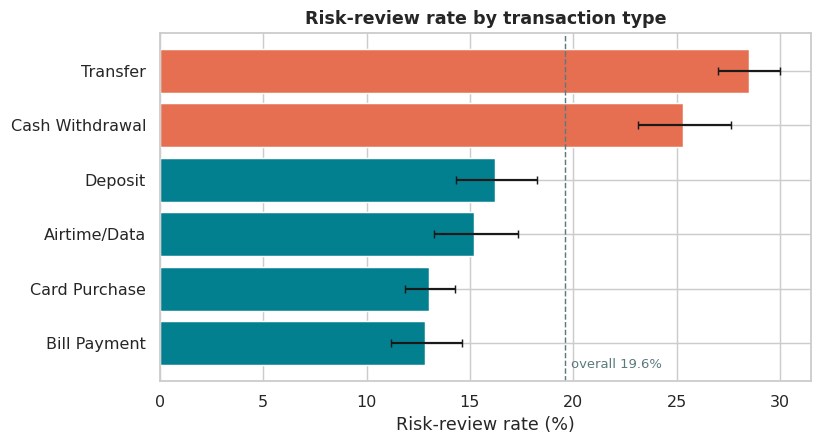

In [5]:
g = transactions.groupby("Transaction_Type").risk.agg(["sum", "count"])g["rate"] = 100 * g["sum"] / g["count"]g["lo"] = [100 * wilson(x, n)[0] for x, n in zip(g["sum"], g["count"])]g["hi"] = [100 * wilson(x, n)[1] for x, n in zip(g["sum"], g["count"])]g = g.sort_values("rate")overall = 100 * transactions.risk.mean()fig, ax = plt.subplots(figsize=(8, 4.3))ax.barh(g.index, g.rate, xerr=[g.rate - g.lo, g.hi - g.rate], color=[CORAL if r > overall + 4 else TEAL for r in g.rate], capsize=3)ax.axvline(overall, color=GREY, ls="--", lw=1); ax.text(overall + 0.3, -0.45, f"overall {overall:.1f}%", color=GREY, fontsize=9)ax.set_xlabel("Risk-review rate (%)"); ax.set_title("Risk-review rate by transaction type", weight="bold")plt.show()print(g[["count", "rate", "lo", "hi"]].round(1).sort_values("rate", ascending=False).to_string())

**What it shows:** the share of transactions flagged for review in each type, with 95% intervals. **Why it matters:** it is theclearest, statistically solid pattern in the data (Cramer's V = 0.17). **Insight:** Transfers (28.5%) and Cash Withdrawals (25.3%)sit well above the 19.6% overall rate and their intervals do not overlap the other four types - review capacity should be aimed there first.

### Chart 2 - International vs domestic risk-review rate within each transaction type

Route             Domestic  International
Transaction_Type                         
Transfer              27.9           42.0
Cash Withdrawal       24.9           40.5
Deposit               15.2           38.6
Card Purchase         12.1           35.2
Airtime/Data          14.4           32.0
Bill Payment          12.3           26.8


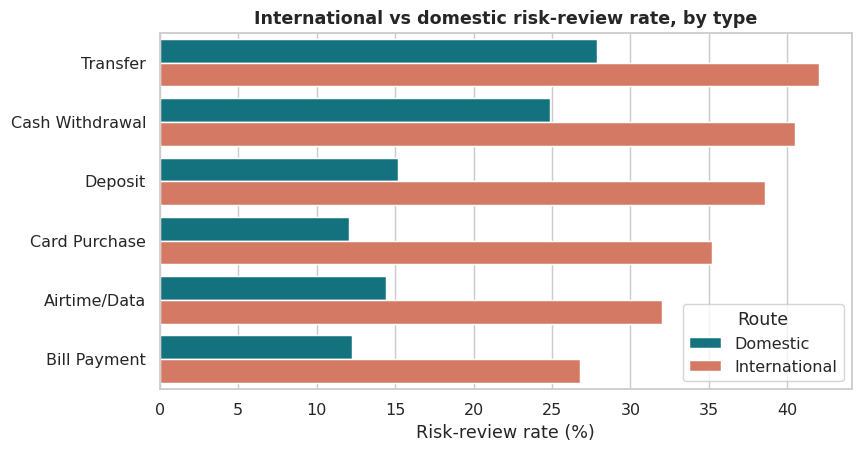

In [6]:
t2 = (transactions.groupby(["Transaction_Type", "International_Transaction"]).risk.mean().mul(100).rename("rate").reset_index())t2["Route"] = t2.International_Transaction.map({"No": "Domestic", "Yes": "International"})order = t2[t2.Route == "International"].sort_values("rate", ascending=False).Transaction_Typefig, ax = plt.subplots(figsize=(8.5, 4.4))sns.barplot(data=t2, y="Transaction_Type", x="rate", hue="Route", order=order, palette={"Domestic": TEAL, "International": CORAL}, ax=ax)ax.set_xlabel("Risk-review rate (%)"); ax.set_ylabel(""); ax.set_title("International vs domestic risk-review rate, by type", weight="bold")plt.show()print(t2.pivot(index="Transaction_Type", columns="Route", values="rate").round(1).loc[order])

**What it shows:** the Week 2 international finding re-tested inside each transaction type. **Why it matters:** it rules out thepossibility that international transactions only look riskier because they happen to be Transfers. **Insight:** international ishigher in all six types (+14 to +23 points) and international volume is a steady ~4% of every type, so the effect is genuine and independent.

### Chart 3 - Value concentration by transaction decile

decile
1     56.15
2     21.25
3     10.62
4      5.58
5      3.01
6      1.65
7      0.89
8      0.47
9      0.25
10     0.11
median NGN 10306.0 | mean NGN 46706.0
Composition of the top decile by type (%): {'Transfer': 51.3, 'Deposit': 25.5, 'Cash Withdrawal': 12.9, 'Card Purchase': 10.2}


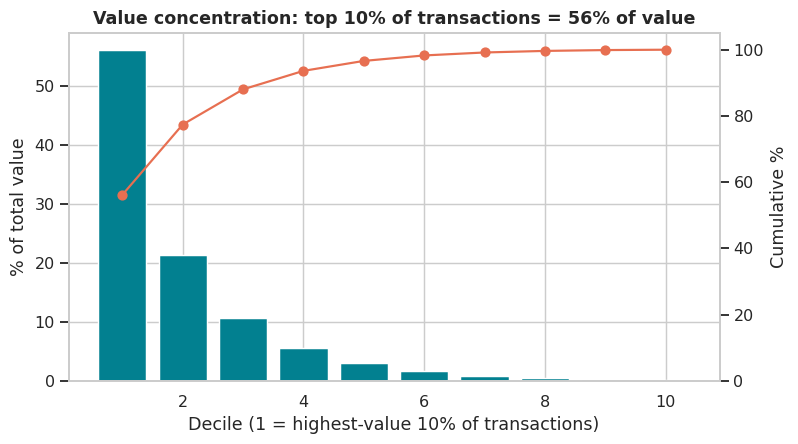

In [7]:
dec = transactions.assign(decile=pd.qcut(transactions.Amount_NGN.rank(method="first", ascending=False), 10, labels=range(1, 11)))dv = dec.groupby("decile", observed=True).Amount_NGN.sum()pct = 100 * dv / dv.sum()fig, ax = plt.subplots(figsize=(8, 4.3))ax.bar(pct.index.astype(int), pct.values, color=TEAL)ax2 = ax.twinx(); ax2.plot(pct.index.astype(int), pct.cumsum().values, color=CORAL, marker="o"); ax2.set_ylim(0, 105); ax2.grid(False)ax.set_xlabel("Decile (1 = highest-value 10% of transactions)"); ax.set_ylabel("% of total value"); ax2.set_ylabel("Cumulative %")ax.set_title("Value concentration: top 10% of transactions = 56% of value", weight="bold")plt.show()print(pct.round(2).to_string())print("median NGN", transactions.Amount_NGN.median().round(0), "| mean NGN", transactions.Amount_NGN.mean().round(0))top = transactions.nlargest(1200, "Amount_NGN").Transaction_Type.value_counts(normalize=True).mul(100).round(1)print("Composition of the top decile by type (%):", top.to_dict())

**What it shows:** how much of the total money sits in each tenth of transactions. **Why it matters:** the mean (NGN 46,706) ismisleading - the median is only about NGN 10,000. **Insight:** decile 1 alone is 56.15% of value and the bottom half of transactionsis just 3.4%; the top decile is mostly Transfers (51%) and Deposits (26%). Value-weighted monitoring protects the most money for the least effort.

### Chart 4 - Risk-review rate by transaction-amount quintile

            count   rate     lo     hi
quintile                              
Q1 lowest    2400  17.83  16.35  19.42
Q2           2400  17.58  16.11  19.16
Q3           2400  17.46  15.99  19.03
Q4           2400  18.38  16.88  19.97
Q5 highest   2400  26.75  25.02  28.56
Q5 starts at NGN 68264


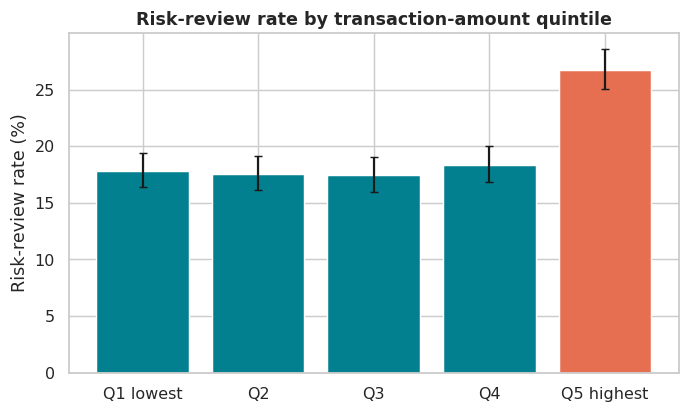

In [8]:
q = transactions.assign(quintile=pd.qcut(transactions.Amount_NGN, 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]))qr = q.groupby("quintile", observed=True).risk.agg(["mean", "sum", "count"])qr["rate"] = 100 * qr["mean"]qr["lo"] = [100 * wilson(x, n)[0] for x, n in zip(qr["sum"], qr["count"])]; qr["hi"] = [100 * wilson(x, n)[1] for x, n in zip(qr["sum"], qr["count"])]fig, ax = plt.subplots(figsize=(7.5, 4.2))ax.bar(qr.index.astype(str), qr.rate, yerr=[qr.rate - qr.lo, qr.hi - qr.rate], color=[TEAL]*4 + [CORAL], capsize=3)ax.set_ylabel("Risk-review rate (%)"); ax.set_title("Risk-review rate by transaction-amount quintile", weight="bold")plt.show()print(qr[["count", "rate", "lo", "hi"]].round(2).to_string())print("Q5 starts at NGN", round(transactions.Amount_NGN.quantile(0.8)))

**What it shows:** whether larger transactions are flagged more often. **Why it matters:** it separates a smooth relationship from athreshold. **Insight:** the rate is flat (about 17.5-18.4%) for the lower four quintiles and rises to 26.8% only in the top 20%(roughly NGN 68,000 and above) - the biggest transactions are both the most valuable and the most often flagged.

### Chart 5 - Monthly value: raw total vs per active day (corrects the Week 3 'dip')

         days  txns  txns_per_day  value_per_day
month                                           
2026-01    31  4133         133.3      6080304.3
2026-02    28  3734         133.4      6278103.5
2026-03    31  4133         133.3      6329065.3


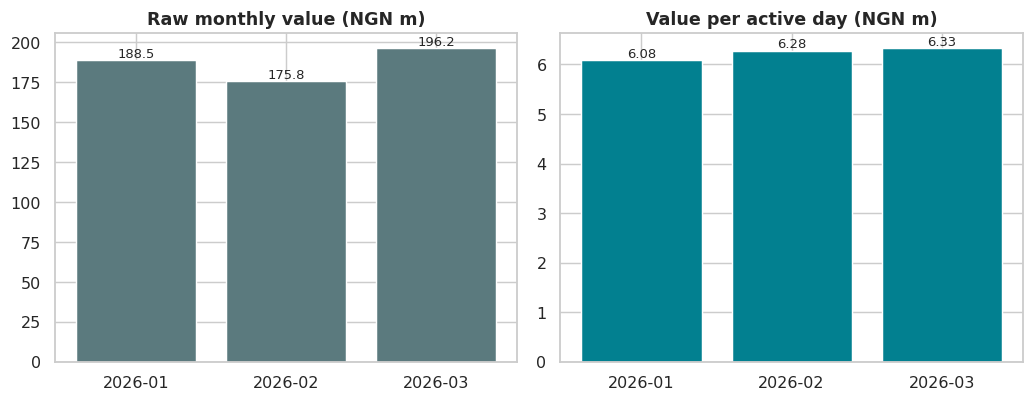

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))labels = [str(m) for m in mt.index]axes[0].bar(labels, mt.value / 1e6, color=GREY); axes[0].set_title("Raw monthly value (NGN m)", weight="bold")axes[1].bar(labels, mt.value_per_day / 1e6, color=TEAL); axes[1].set_title("Value per active day (NGN m)", weight="bold")for ax, series in zip(axes, [mt.value / 1e6, mt.value_per_day / 1e6]):    for i, v in enumerate(series): ax.text(i, v, f"{v:.1f}" if v > 50 else f"{v:.2f}", ha="center", va="bottom", fontsize=9)plt.tight_layout(); plt.show()print(mt[["days", "txns", "txns_per_day", "value_per_day"]].round(1).to_string())

**What it shows:** the same three months measured two ways. **Why it matters:** February has only 28 days, so a raw total will alwayslook lower. **Insight:** per active day, volume is identical (about 133 transactions) and value is slightly higher in February than January.The "February dip" reported in Week 3 does not exist - months must be compared per day.

### Chart 6 - Failed/Reversed rate by channel (95% confidence intervals)

            count  rate    lo     hi
Channel                             
USSD          889  8.66  6.99  10.69
Mobile App   5102  8.64  7.90   9.45
POS          2393  7.73  6.73   8.87
Web          1869  7.12  6.04   8.37
ATM          1747  6.87  5.78   8.15

Failed+Reversed: 956 transactions (7.97%), NGN 40,451,869 = 7.22% of value


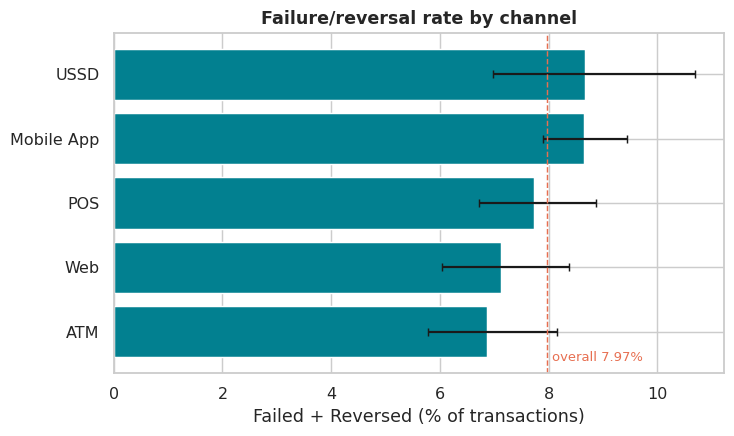

In [10]:
ch = transactions.groupby("Channel").bad.agg(["sum", "count"])ch["rate"] = 100 * ch["sum"] / ch["count"]ch["lo"] = [100 * wilson(x, n)[0] for x, n in zip(ch["sum"], ch["count"])]; ch["hi"] = [100 * wilson(x, n)[1] for x, n in zip(ch["sum"], ch["count"])]ch = ch.sort_values("rate")overall_bad = 100 * transactions.bad.mean()fig, ax = plt.subplots(figsize=(7.5, 4.2))ax.barh(ch.index, ch.rate, xerr=[ch.rate - ch.lo, ch.hi - ch.rate], color=TEAL, capsize=3)ax.axvline(overall_bad, color=CORAL, ls="--", lw=1); ax.text(overall_bad + 0.1, -0.45, f"overall {overall_bad:.2f}%", color=CORAL, fontsize=9)ax.set_xlabel("Failed + Reversed (% of transactions)"); ax.set_title("Failure/reversal rate by channel", weight="bold")plt.show()print(ch[["count", "rate", "lo", "hi"]].round(2).sort_values("rate", ascending=False).to_string())value_lost = transactions[transactions.bad].Amount_NGN.sum()print(f"\nFailed+Reversed: {transactions.bad.sum()} transactions ({overall_bad:.2f}%), NGN {value_lost:,.0f} = {100*value_lost/transactions.Amount_NGN.sum():.2f}% of value")

**What it shows:** how often transactions fail or reverse on each channel, with uncertainty. **Why it matters:** it tests whether anychannel is a genuine reliability hotspot. **Insight:** all five intervals overlap the 7.97% overall rate and the chi-square test is notsignificant (p = 0.07) - failures look like a platform-wide issue (NGN 40.5m, 7.2% of value) rather than a single-channel problem. ATM looksbest but only borderline. Targeting one channel on this evidence would be premature.

### Chart 7 - Where customers live vs where transactions are recorded

               Customers by home city  Value by home city  Value by transaction location
Lagos                            32.5                33.9                           11.5
Abuja                            14.9                14.9                           11.2
Port Harcourt                    11.5                11.4                           12.8
Kano                             10.6                10.8                           13.4
Ibadan                            9.9                10.0                           14.6
Enugu                             7.2                 7.1                           12.4
Kaduna                            6.9                 6.4                           12.7
Benin City                        6.6                 5.5                           11.4


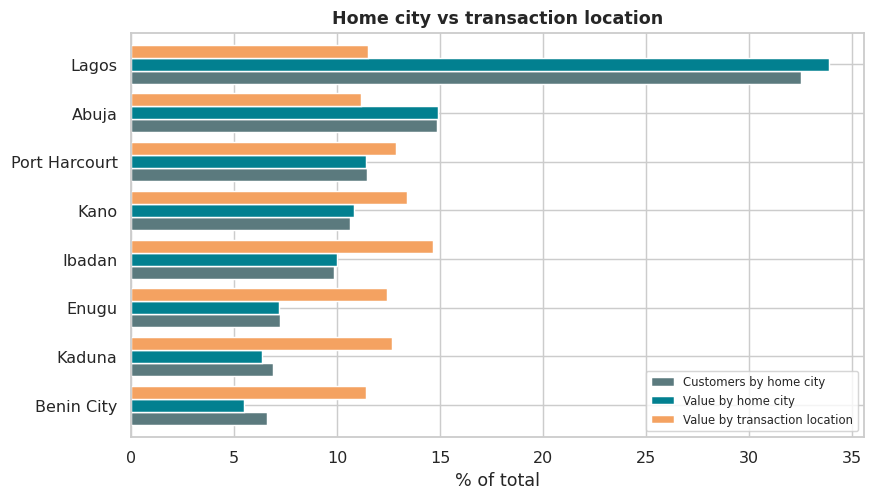

In [11]:
home = customers.City.value_counts(normalize=True).mul(100).rename("Customers by home city")val_home = merged.groupby("City").Amount_NGN.sum().pipe(lambda s: 100 * s / s.sum()).rename("Value by home city")val_loc = transactions.dropna(subset=["Location"]).groupby("Location").Amount_NGN.sum().pipe(lambda s: 100 * s / s.sum()).rename("Value by transaction location")geo = pd.concat([home, val_home, val_loc], axis=1).sort_values("Customers by home city")ax = geo.plot(kind="barh", figsize=(9, 5), color=[GREY, TEAL, AMBER], width=0.8)ax.set_xlabel("% of total"); ax.set_ylabel(""); ax.set_title("Home city vs transaction location", weight="bold"); ax.legend(loc="lower right", fontsize=8)plt.show()print(geo.round(1).sort_values("Customers by home city", ascending=False).to_string())

**What it shows:** three geographic views side by side. **Why it matters:** "Lagos" can mean where customers *live* or where transactions are *recorded*,and they are different questions. **Insight:** Lagos has 32.5% of customers and 33.9% of value by home city - proportional to its customer count - but only11.5% of value by transaction location, where all eight cities sit between 11% and 15%. The two fields are statistically unrelated, so City answerscustomer-base questions and Location answers where activity is recorded.

## 6. Summary of final conclusions| # | Conclusion | Status ||---|---|---|| 1 | Risk-review concentrates in Transfers (28.5%) and Cash Withdrawals (25.3%) | Supported || 2 | International transactions are flagged ~2x as often, in every transaction type | Supported (the "narrowing" claim was not) || 3 | Top 10% of transactions = 56% of value; top 20% by amount are flagged more (26.8%) | Supported || 4 | Failures/reversals (7.97%, NGN 40.5m) are spread across channels, types and segments | New - replaces "Web is worst" || 5 | Segments do not differ on value, frequency, engagement or risk | New - replaces two Week 2-3 segment claims || 6 | Months must be compared per day; there is no February dip | Corrected || 7 | Home city and transaction location are unrelated; Lagos is a customer-base fact | Supported |**Limitations:** synthetic data (the daily and hourly volumes are almost perfectly uniform, so time-of-day or seasonal patterns cannot be studied);associations are not causes; `Risk_Review_Flag` is an educational label, not evidence of fraud; no failure-reason field exists to explain *why* transactions fail.